# Forecasting Next-Year GDP Growth Across Countries
### Modelling and Validation

**Module:** CSC1181 / CSC1203 Machine Learning Project<br>
**Workstream:** Preprocessing, models and validation<br>
**Author:** Sami Haroon Khan<br>
**Team:** Farhana Ahmed, Sami Haroon Khan, Sukesh Babu Ramesh Babu, Parthiban Sathappan Tamilselvi

---

**Question.** Can a machine learning model predict a country's GDP growth for next year from this year's economic indicators, and does it beat simple benchmarks and the IMF's own forecasts?

**Data.** World Bank WDI and IMF WEO, 217 economies, input years 2000-2023. Each row is one country in input year *t*, and the target is GDP growth in year *t+1*.

> **Key results**
> - In normal years (2008-2019 backtest), the models are about 10% more accurate than the best simple benchmark: MAE 2.80 vs 3.11 percentage points. A country-level bootstrap shows this gain is real.
> - At turning points (2009, 2020, 2021) every method fails. In 2021 the plain global average beats the models, because the models trusted the 2020 COVID crash.
> - On the 2021-2024 test the models and the average benchmarks are statistically tied. On 2022-2024 the models win again.
> - Current GDP growth carries most of the signal. Lasso drops unemployment, inflation, government debt and current account.
> - **Forecasts:** the median country grows 3.2% in 2026 (IMF: 3.0%) and 2.95% in 2027 under the IMF outlook. In a global-slowdown scenario that falls to 2.3%. The 80% uncertainty band is about +/- 4 pp.

### Contents
1. [Setup](#s0)
2. [Data and leakage checks](#s1)
3. [Region and income group](#s2)
4. [Models: baselines, tuning, results](#s3)
5. [Feature importance and figures](#s4)
6. [Comparison with IMF forecasts](#s5)
7. [Robustness checks](#s6)
8. [Forecasts for 2026 and 2027, with editable assumptions](#s7)
9. [Conclusions and limitations](#s8)

<a id="s0"></a>
## 0. Setup
All imports, paths and the plot style live in one place. Baselines are drawn grey and dashed, and models in colour, in every figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import HTML, display
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

DATA = Path("../merged_data/merged_data")
OUT = Path("outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
TARGET = "next_year_gdp_growth"

BASELINES = ["Naive", "Global mean", "Country mean"]
MODELS = ["Ridge", "Lasso", "Random Forest", "Gradient Boosting"]
ORDER = BASELINES + MODELS
# Chart palette: one fixed colour per method in every figure, checked for colour-blind safety
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, GRAY_BAR = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
LINES = {"Gradient Boosting": dict(color=BLUE, lw=2.2),
         "Global mean": dict(color=ORANGE, lw=1.8),
         "Country mean": dict(color=AQUA, lw=1.8),
         "Naive": dict(color=MUTED, lw=1.5, ls=(0, (4, 2)))}
PERIODS = {"val": "Validation 2018-19", "covid": "COVID 2020", "test": "Test 2021-24"}

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 8.5, "figure.facecolor": "white",
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white"})

def headline(fig, title, subtitle, handles=None, labels=None, ncol=5, pad=6):
    # takeaway title, subtitle and legend above the plot, all lined up with the leftmost label
    fig.canvas.draw()
    x0 = fig.get_tightbbox().x0 / fig.get_figwidth()
    pt = 1 / 72 / fig.get_figheight()
    y = max(a.get_position().y1 for a in fig.axes) + pad * pt
    if handles:
        fig.legend(handles, labels, ncol=ncol, loc="lower left", bbox_to_anchor=(x0, y), borderaxespad=0,
                   handlelength=2.2, columnspacing=1.4)
        y += 20 * pt
    fig.text(x0, y + 4 * pt, subtitle, fontsize=9, color=INK2, ha="left", va="bottom")
    fig.text(x0, y + 20 * pt, title, fontsize=11, fontweight="bold", color=INK, ha="left", va="bottom")

def year_lines(ax, table, models):
    # Gradient Boosting line, a pale band for the range of all ML models, and the three baselines
    ax.fill_between(table.index, table[models].min(axis=1), table[models].max(axis=1),
                    color=BLUE, alpha=0.12, lw=0, label="Range across ML models")
    for m, kw in LINES.items():
        ax.plot(table.index, table[m], marker="o", ms=4.5, mec="white", mew=1, label=m, **kw)
    ax.yaxis.grid(True); ax.spines["left"].set_visible(False)
    ax.set_ylim(0, 12.8)

def show(df, fmt="{:.2f}", best=None, axis=0):
    """Show a table with fixed decimals. best='min' or 'max' puts the best value of each column (axis=0)
    or row (axis=1) in bold. Plain HTML, so the bold also shows on GitHub."""
    out = df.astype(object).copy()
    for c in df.columns:
        f = fmt.get(c) if isinstance(fmt, dict) else fmt
        if f and pd.api.types.is_numeric_dtype(df[c]):
            out[c] = df[c].map(lambda v: "" if pd.isna(v) else f.format(v))
    if best:
        num = df.select_dtypes("number")
        target = num.min(axis=axis) if best == "min" else num.max(axis=axis)
        mask = num.eq(target, axis=1 - axis).reindex(columns=df.columns, fill_value=False)
        out = out.where(~mask, "<b>" + out.astype(str) + "</b>")
    display(HTML(out.to_html(escape=False)))

<a id="s1"></a>
## 1. Data and leakage checks

### 1.1 Load the four splits
Farhana's four time-based CSV files are stacked into one table, `panel`. The split is by **target year**: train 2001-2017, validation 2018-2019, COVID 2020 and test 2021-2024.

### 1.2 Leakage checks
- Every country has all 24 input years (2000-2023), so the previous row is always the previous year.
- The target year is always the input year + 1.
- No two splits share a target year.

If any check fails, the notebook stops here.

In [2]:
files = {"train": "GDP_Training_2001_2017.csv", "val": "GDP_Validation_2018_2019.csv",
         "covid": "GDP_COVID_2020.csv", "test": "GDP_Testing_2021_2024.csv"}
panel = pd.concat([pd.read_csv(DATA / f).assign(split=s) for s, f in files.items()], ignore_index=True)
panel = panel.sort_values(["Country Code", "Year"]).reset_index(drop=True)

assert panel.groupby("Country Code")["Year"].apply(lambda y: list(y) == list(range(2000, 2024))).all()
assert (panel["target_year"] == panel["Year"] + 1).all()
yrs = panel.groupby("split")["target_year"].agg(["min", "max"])
assert yrs.loc["train", "max"] < yrs.loc["val", "min"] <= yrs.loc["val", "max"] < yrs.loc["covid", "min"] < yrs.loc["test", "min"]

summary = panel.groupby("split").agg(rows=("Country Code", "size"), first_target_year=("target_year", "min"),
                                     last_target_year=("target_year", "max")).loc[["train", "val", "covid", "test"]]
print("All leakage checks passed.")
show(summary, fmt="{:,.0f}")

All leakage checks passed.


,rows,first_target_year,last_target_year
split,,,
train,"3,689","2,001","2,017"
val,434,"2,018","2,019"
covid,217,"2,020","2,020"
test,868,"2,021","2,024"


### 1.3 Feature engineering and gaps
- **Two lag features:** last year's growth (`gdp_growth_lag1`) and the 3-year average growth (`gdp_growth_avg3`). With the 8 indicators that gives **10 features**, within the guideline of about 10.
- **Gaps** are filled with the same country's most recent earlier value. The rows are sorted by year, so this never looks into the future. Whatever is still missing is filled later with the training median.
- **Naive baseline:** next year's growth = this year's growth.

In [3]:
g = panel.groupby("Country Code")["gdp_growth"]
panel["gdp_growth_lag1"] = g.shift(1)
panel["gdp_growth_avg3"] = g.transform(lambda s: s.rolling(3, min_periods=2).mean())

BASE = ["gdp_growth", "inflation", "unemployment", "trade", "investment",
        "population_growth", "government_debt", "current_account"]
FEATURES = BASE + ["gdp_growth_lag1", "gdp_growth_avg3"]

before = panel[FEATURES].isna().mean().mul(100)
panel[FEATURES] = panel.groupby("Country Code")[FEATURES].ffill()
panel["naive"] = panel["gdp_growth"]
show(pd.DataFrame({"missing before (%)": before, "missing after fill (%)": panel[FEATURES].isna().mean().mul(100)}), fmt="{:.1f}")

,missing before (%),missing after fill (%)
gdp_growth,4.6,3.4
inflation,16.4,14.6
unemployment,13.9,13.8
trade,17.9,15.5
investment,21.2,18.8
population_growth,0.0,0.0
government_debt,14.5,14.2
current_account,13.9,13.6
gdp_growth_lag1,8.5,7.5
gdp_growth_avg3,8.5,7.9


<a id="s2"></a>
## 2. Region and income group
These come from the public World Bank country API. They are downloaded once and cached in `outputs/country_groups.csv`, so later runs work offline. They let the team break errors down by region and income group.

*Limitation:* this is the **current** income classification, applied to every year.

In [4]:
gfile = OUT / "country_groups.csv"
if not gfile.exists():
    import requests
    js = requests.get("https://api.worldbank.org/v2/country?format=json&per_page=400", timeout=30).json()[1]
    pd.DataFrame([{"Country Code": c["id"], "region": c["region"]["value"],
                   "income_group": c["incomeLevel"]["value"]} for c in js]).to_csv(gfile, index=False)
groups = pd.read_csv(gfile)
missing = set(panel["Country Code"]) - set(groups["Country Code"])
assert not missing, missing
counts = groups[groups["Country Code"].isin(panel["Country Code"])]["income_group"].value_counts()
show(counts.rename("economies").to_frame(), fmt="{:,.0f}")

,economies
income_group,
High income,86
Upper middle income,59
Lower middle income,47
Low income,25


<a id="s3"></a>
## 3. Models

### 3.1 Outliers
The training data includes hyperinflation (514%) and growth of +87%. Each feature is clipped at its **training** 1st and 99th percentile. The target is never clipped, because the true outcome is never changed. An unclipped copy (`raw`) is kept for the backtest in Section 6.

In [5]:
raw = panel.copy()
tr = panel["split"] == "train"
lo = panel.loc[tr, FEATURES].quantile(0.01)
hi = panel.loc[tr, FEATURES].quantile(0.99)
panel[FEATURES] = panel[FEATURES].clip(lo, hi, axis=1)
show(pd.DataFrame({"lower cap": lo, "upper cap": hi}), fmt="{:.1f}")

,lower cap,upper cap
gdp_growth,-10.9,17.3
inflation,-2.4,44.4
unemployment,0.6,27.7
trade,22.6,358.7
investment,3.6,52.8
population_growth,-2.0,6.1
government_debt,2.0,225.3
current_account,-32.0,40.7
gdp_growth_lag1,-11.0,17.3
gdp_growth_avg3,-7.9,14.4


### 3.2 Pipeline and candidate settings
- **Pipeline:** median imputer, then standard scaler, then the model. Because these steps are chained, they are learned only from the rows the model is trained on.
- **Why these four models:**
  - Ridge handles correlated indicators.
  - Lasso does feature selection.
  - Random Forest captures non-linear effects and is robust to outliers.
  - Gradient Boosting is a strong tabular learner; Huber loss makes it less sensitive to extreme years.
- **Common rows:** every method is scored on the same rows, those where both the actual value and the naive guess exist.

In [6]:
def make_pipe(model):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

CANDIDATES = {
    "Ridge": [Ridge(alpha=a) for a in (0.1, 1, 10, 100)],
    "Lasso": [Lasso(alpha=a, max_iter=10000) for a in (0.01, 0.05, 0.1, 0.5)],
    "Random Forest": [RandomForestRegressor(n_estimators=300, max_depth=d, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1) for d in (4, 8, None)],
    "Gradient Boosting": [GradientBoostingRegressor(n_estimators=n, learning_rate=0.05, max_depth=3,
                                                    loss="huber", random_state=42) for n in (100, 300)],
}

def mae(y, p): return float(np.mean(np.abs(y - p)))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))

scored = panel.dropna(subset=[TARGET, "naive"])
train, val = scored[scored.split == "train"], scored[scored.split == "val"]
print(f"Training rows: {len(train):,}   Validation rows: {len(val):,}")

Training rows: 3,500   Validation rows: 421


### 3.3 Hyperparameter tuning
Each setting is trained on 2001-2017 and scored on 2018-2019. For each model, the setting with the lowest validation MAE is kept. The test years are never used for any choice.

In [7]:
best, tuning = {}, []
for name, cands in CANDIDATES.items():
    scores = []
    for m in cands:
        p = make_pipe(m).fit(train[FEATURES], train[TARGET]).predict(val[FEATURES])
        scores.append(mae(val[TARGET], p))
        keys = ("n_estimators",) if name == "Gradient Boosting" else ("alpha", "max_depth")
        setting = ", ".join(f"{k} = {v}" for k, v in m.get_params(deep=False).items() if k in keys)
        tuning.append({"model": name, "setting": setting, "validation MAE": scores[-1], "chosen": ""})
    pick = int(np.argmin(scores))
    best[name] = cands[pick]
    tuning[len(tuning) - len(cands) + pick]["chosen"] = "yes"
tuning = pd.DataFrame(tuning).set_index(["model", "setting"])
print(f"Naive baseline validation MAE: {mae(val[TARGET], val['naive']):.3f}")
show(tuning, fmt={"validation MAE": "{:.3f}"})

Naive baseline validation MAE: 2.161


### 3.4 Final fit and predictions
- **Validation predictions** come from the fit on 2001-2017.
- **COVID (2020) and test (2021-2024) predictions** come from a refit on 2001-2019.
- **Three simple baselines:**
  - *Naive* (next year = this year);
  - *Global mean* (everyone gets the average training growth);
  - *Country mean* (each country's own training average).
- **Output:** `outputs/predictions_all_models.csv`, the team's common evaluation table (country, target year, actual, predicted, model, region, income group).

In [8]:
rows = []
def add(df, pred, model):
    rows.append(df[["Country Name", "Country Code", "target_year", "split"]]
                .assign(actual=df[TARGET].values, predicted=pred, model=model))

trval = scored[scored.split.isin(["train", "val"])]
later = scored[scored.split.isin(["covid", "test"])]
for name, m in best.items():
    add(val, make_pipe(m).fit(train[FEATURES], train[TARGET]).predict(val[FEATURES]), name)
    add(later, make_pipe(m).fit(trval[FEATURES], trval[TARGET]).predict(later[FEATURES]), name)
for fit_rows, part in ((train, val), (trval, later)):
    add(part, part["naive"].values, "Naive")
    gm, cm = fit_rows[TARGET].mean(), fit_rows.groupby("Country Code")[TARGET].mean()
    add(part, np.full(len(part), gm), "Global mean")
    add(part, part["Country Code"].map(cm).fillna(gm).values, "Country mean")

preds = pd.concat(rows, ignore_index=True).merge(groups, on="Country Code", how="left")
assert preds["region"].notna().all()
preds.to_csv(OUT / "predictions_all_models.csv", index=False, float_format="%.4f")
print(f"Saved {len(preds):,} predictions ({preds['model'].nunique()} methods) to outputs/predictions_all_models.csv")

Saved 10,178 predictions (7 methods) to outputs/predictions_all_models.csv


### 3.5 Results
MAE is the main metric because a few extreme country-years dominate RMSE. Both are in percentage points of GDP growth. The best value in each column is shown in **bold**.

In [9]:
def score(d): return pd.Series({"MAE": mae(d.actual, d.predicted), "RMSE": rmse(d.actual, d.predicted), "n": len(d)})
metrics = preds.groupby(["split", "model"]).apply(score).reset_index()
by_year = preds.groupby(["target_year", "model"]).apply(score)["MAE"].unstack()
metrics.round(3).to_csv(OUT / "metrics_by_split.csv", index=False)
by_year.round(2).to_csv(OUT / "metrics_by_year.csv")

n = metrics.groupby("split")["n"].first()
label = {s: f"{PERIODS[s]} (n={int(n[s])})" for s in PERIODS}
for metric in ["MAE", "RMSE"]:
    print(metric)
    show(metrics.pivot(index="model", columns="split", values=metric).loc[ORDER, list(PERIODS)].rename(columns=label), best="min")

MAE


split,Validation 2018-19 (n=421),COVID 2020 (n=210),Test 2021-24 (n=823)
model,,,
Naive,2.16,8.65,5.81
Global mean,2.51,9.61,3.35
Country mean,2.38,9.60,3.54
Ridge,1.90,9.08,3.72
Lasso,1.90,9.09,3.71
Random Forest,1.85,8.97,3.49
Gradient Boosting,1.90,9.16,3.47


RMSE


split,Validation 2018-19 (n=421),COVID 2020 (n=210),Test 2021-24 (n=823)
model,,,
Naive,5.16,11.23,10.54
Global mean,3.91,12.47,6.24
Country mean,3.85,12.43,6.39
Ridge,3.41,11.74,6.76
Lasso,3.41,11.75,6.75
Random Forest,3.45,11.72,6.35
Gradient Boosting,3.51,11.81,6.46


> **Reading the table.**
> - On validation, every model beats every baseline.
> - In 2020 nothing works.
> - On the 2021-2024 test, the global mean is lowest. The yearly breakdown below shows this comes from 2021 alone.

In [10]:
show(by_year[ORDER], best="min", axis=1)

model,Naive,Global mean,Country mean,Ridge,Lasso,Random Forest,Gradient Boosting
target_year,,,,,,,
2018,2.33,2.32,2.13,1.68,1.67,1.64,1.69
2019,1.99,2.69,2.64,2.13,2.13,2.06,2.12
2020,8.65,9.61,9.60,9.08,9.09,8.97,9.16
2021,11.92,4.18,4.57,6.42,6.39,5.52,5.71
2022,4.86,3.76,4.09,3.61,3.60,3.68,3.49
2023,3.89,2.96,3.02,2.81,2.81,2.72,2.65
2024,2.36,2.43,2.43,1.90,1.91,1.93,1.95


<a id="s4"></a>
## 4. Feature importance and figures

### 4.1 Permutation importance
Shuffle one feature on the validation years and measure how much the MAE gets worse. The same method works for every model. The Lasso coefficients show which features Lasso removed (coefficient = 0).

In [11]:
imp = {}
for name, m in best.items():
    fitted = make_pipe(m).fit(train[FEATURES], train[TARGET])
    r = permutation_importance(fitted, val[FEATURES], val[TARGET], scoring="neg_mean_absolute_error",
                               n_repeats=20, random_state=42)
    imp[name] = r.importances_mean
imp = pd.DataFrame(imp, index=FEATURES)
imp.round(3).to_csv(OUT / "feature_importance.csv")

lasso_coef = pd.Series(make_pipe(best["Lasso"]).fit(train[FEATURES], train[TARGET])[-1].coef_, index=FEATURES)
show(imp.assign(**{"Lasso coefficient": lasso_coef}).sort_values("Gradient Boosting", ascending=False), fmt="{:.3f}")

,Ridge,Lasso,Random Forest,Gradient Boosting,Lasso coefficient
gdp_growth,0.649,0.639,0.634,0.515,1.639
gdp_growth_avg3,0.021,0.030,0.138,0.154,0.214
population_growth,0.028,0.025,0.006,0.051,0.295
unemployment,-0.001,0.000,-0.002,0.019,0.000
investment,0.006,0.001,-0.001,0.002,0.016
gdp_growth_lag1,0.038,0.035,-0.006,-0.004,0.332
trade,0.004,0.000,0.000,-0.004,-0.010
inflation,0.000,0.000,0.009,-0.005,0.000
government_debt,-0.004,0.000,0.007,-0.006,0.000
current_account,-0.001,0.000,0.000,-0.010,0.000


### 4.2 Report figures
- **Figure 1:** MAE by method, for validation and test.
- **Figure 2:** MAE by target year, including 2020.
- **Figure 3:** feature importance.

Each method keeps the same colour in every figure. Gradient Boosting is blue, with a pale band showing the range across all the ML models. The global mean is orange, the country mean aqua, and naive a gray dashed line. The palette was checked for colour-blind safety. Figures are saved at 300 dpi to `outputs/figures/`.

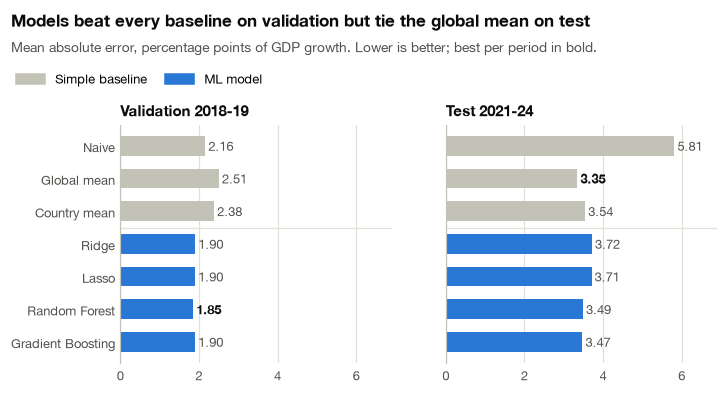

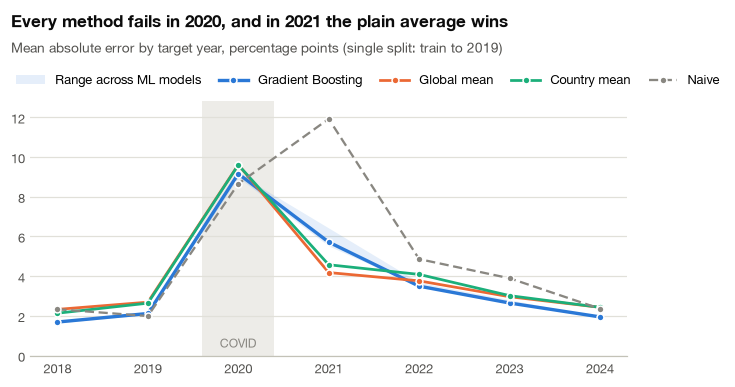

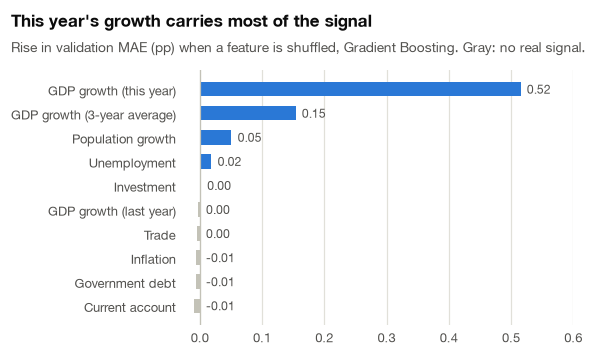

In [12]:
# Figure 1: validation and test side by side (COVID 2020 is shown in Figure 2)
mae_tab = metrics.pivot(index="model", columns="split", values="MAE").loc[ORDER]
y = np.arange(len(ORDER))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=True)
for ax, per in zip(axes, ["val", "test"]):
    v = mae_tab[per]
    ax.barh(y, v.values, height=0.6, color=[GRAY_BAR if m in BASELINES else BLUE for m in ORDER])
    for yi, m in zip(y, ORDER):
        top = m == v.idxmin()
        ax.text(v[m] + 0.08, yi, f"{v[m]:.2f}", va="center", fontsize=8.5,
                color=INK if top else INK2, fontweight="bold" if top else "normal")
    ax.axhline(y[len(BASELINES) - 1] - 0.5, color=GRID, lw=0.8)
    ax.set_title(PERIODS[per], loc="left", fontsize=9.5, fontweight="bold", color=INK)
    ax.set_xlim(0, 6.9); ax.xaxis.grid(True); ax.spines["bottom"].set_visible(False)
axes[0].set_yticks(y, ORDER)
handles = [plt.Rectangle((0, 0), 1, 1, color=GRAY_BAR), plt.Rectangle((0, 0), 1, 1, color=BLUE)]
headline(fig, "Models beat every baseline on validation but tie the global mean on test",
         "Mean absolute error, percentage points of GDP growth. Lower is better; best per period in bold.",
         handles, ["Simple baseline", "ML model"], ncol=2, pad=22)
fig.savefig(OUT / "figures/mae_by_model.png"); plt.show()

# Figure 2: error by target year, including the COVID year
fig, ax = plt.subplots(figsize=(7.0, 3.0))
ax.axvspan(2019.6, 2020.4, color=GRID, alpha=0.6, lw=0)
ax.text(2020, 0.4, "COVID", ha="center", fontsize=8, color=MUTED)
year_lines(ax, by_year, MODELS)
ax.set_xticks(by_year.index)
headline(fig, "Every method fails in 2020, and in 2021 the plain average wins",
         "Mean absolute error by target year, percentage points (single split: train to 2019)",
         *ax.get_legend_handles_labels())
fig.savefig(OUT / "figures/mae_by_year.png"); plt.show()

# Figure 3: feature importance with readable names
NAMES = {"gdp_growth": "GDP growth (this year)", "gdp_growth_avg3": "GDP growth (3-year average)",
         "gdp_growth_lag1": "GDP growth (last year)", "population_growth": "Population growth",
         "unemployment": "Unemployment", "investment": "Investment", "trade": "Trade",
         "inflation": "Inflation", "government_debt": "Government debt", "current_account": "Current account"}
v = imp["Gradient Boosting"].sort_values()
fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.barh([NAMES[f] for f in v.index], v.values, height=0.6, color=[BLUE if x > 0.01 else GRAY_BAR for x in v])
for yi, x in enumerate(v):
    ax.text(max(x, 0) + 0.01, yi, f"{abs(x):.2f}" if abs(x) < 0.005 else f"{x:.2f}", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=AXIS, lw=0.8); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
ax.xaxis.grid(True); ax.set_xlim(-0.03, 0.6)
headline(fig, "This year's growth carries most of the signal",
         "Rise in validation MAE (pp) when a feature is shuffled, Gradient Boosting. Gray: no real signal.")
fig.savefig(OUT / "figures/feature_importance.png"); plt.show()

<a id="s5"></a>
## 5. Comparison with IMF forecasts
This section needs Farhana's file `../merged_data/imf_benchmark/imf_forecasts.csv` with the columns `Country Code, target_year, imf_forecast`. Each forecast should be from the October WEO of year *t*, forecasting *t+1*.

Every method is scored only on the rows the IMF covers, so the comparison is like for like. Until the file exists, the cell just reports that it is missing.

*Caveat:* the IMF forecasts before year *t* ends, while our models use full-year data. That slightly favours our models.

In [13]:
imf_file = DATA.parent / "imf_benchmark" / "imf_forecasts.csv"
if imf_file.exists():
    imf = pd.read_csv(imf_file)
    m = preds.merge(imf, on=["Country Code", "target_year"], how="inner")
    imf_rows = m.drop_duplicates(["Country Code", "target_year"]).assign(model="IMF", predicted=lambda d: d.imf_forecast)
    both = pd.concat([m, imf_rows], ignore_index=True)
    vs_imf = both.groupby(["split", "model"]).apply(score).round(3).reset_index()
    vs_imf.to_csv(OUT / "metrics_vs_imf.csv", index=False)
    show(vs_imf.pivot(index="model", columns="split", values="MAE"), best="min")
else:
    print("IMF benchmark file not in the repo yet:", imf_file)

IMF benchmark file not in the repo yet: ../merged_data/imf_benchmark/imf_forecasts.csv


<a id="s6"></a>
## 6. Robustness checks
A single train/test split gives one number per period. The checks below test whether those numbers can be trusted.

### 6.1 Expanding-window backtest
For each target year *Y* (2008-2019 and 2021-2024), every method is refit on **all years before Y** and then forecasts *Y*. This is how a forecaster would really work, and it gives 16 test years instead of one.

- The clipping cut-offs and the imputer are refit every time.
- 2020 is left out of training as a one-off shock. The first table checks that choice.

In [14]:
def fit_predict(model, tr, te, feats=FEATURES, clip=True):
    tr, te = tr.copy(), te.copy()
    if clip:
        lo, hi = tr[feats].quantile(0.01), tr[feats].quantile(0.99)
        tr[feats], te[feats] = tr[feats].clip(lo, hi, axis=1), te[feats].clip(lo, hi, axis=1)
    return make_pipe(clone(model)).fit(tr[feats], tr[TARGET]).predict(te[feats])

rs = raw.dropna(subset=[TARGET, "naive"])
BT = ["Naive", "Global mean", "Country mean", "Ridge", "Random Forest", "Gradient Boosting"]
errs = []
for Y in list(range(2008, 2020)) + [2021, 2022, 2023, 2024]:
    for incl2020 in ([False, True] if Y >= 2022 else [False]):
        tr = rs[(rs.target_year < Y) & ((rs.target_year != 2020) | incl2020)]
        te = rs[rs.target_year == Y]
        gm, cm = tr[TARGET].mean(), tr.groupby("Country Code")[TARGET].mean()
        e = te[["Country Code", "target_year"]].assign(incl2020=incl2020)
        e["Naive"] = (te[TARGET] - te.naive).abs().values
        e["Global mean"] = (te[TARGET] - gm).abs().values
        e["Country mean"] = (te[TARGET] - te["Country Code"].map(cm).fillna(gm)).abs().values
        for name in ["Ridge", "Random Forest", "Gradient Boosting"]:
            e[name] = np.abs(te[TARGET].values - fit_predict(best[name], tr, te))
        errs.append(e)
E = pd.concat(errs)

print("Does adding 2020 to training help 2022-2024? (MAE)")
show(E[E.target_year >= 2022].groupby("incl2020")[["Ridge", "Random Forest", "Gradient Boosting"]].mean()
     .rename(index={False: "2020 excluded", True: "2020 included"}), fmt="{:.3f}", best="min")

E = E[~E.incl2020]
backtest = E.groupby("target_year")[BT].mean()
backtest.round(2).to_csv(OUT / "backtest_by_year.csv")
print("MAE per target year (best method per year in bold)")
show(backtest, best="min", axis=1)

Does adding 2020 to training help 2022-2024? (MAE)


,Ridge,Random Forest,Gradient Boosting
incl2020,,,
2020 excluded,2.913,2.801,2.703
2020 included,2.965,2.848,2.734


MAE per target year (best method per year in bold)


,Naive,Global mean,Country mean,Ridge,Random Forest,Gradient Boosting
target_year,,,,,,
2008,3.59,3.41,3.13,3.20,3.27,3.24
2009,5.38,6.09,5.88,5.87,5.75,5.76
2010,5.11,3.31,3.05,3.20,2.99,3.10
2011,3.41,3.38,3.22,2.98,2.89,3.02
2012,4.03,4.17,3.61,3.40,3.45,3.43
2013,3.54,3.13,2.83,2.46,2.47,2.42
2014,2.47,2.55,2.48,1.97,2.05,1.98
2015,2.41,2.81,2.89,2.30,2.21,2.25
2016,2.41,2.59,2.62,2.07,2.13,2.13


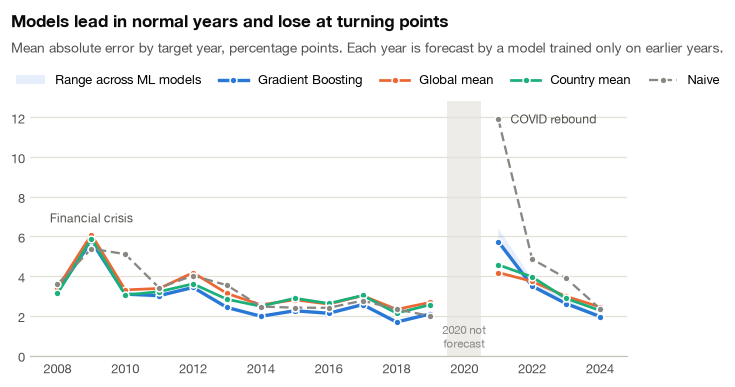

In [15]:
# Figure 4: the expanding-window backtest (the main figure for the report)
bt = backtest.reindex(range(2008, 2025))   # the empty 2020 row breaks the lines
fig, ax = plt.subplots(figsize=(7.0, 3.0))
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, lw=0)
ax.text(2020, 0.4, "2020 not\nforecast", ha="center", fontsize=7.5, color=MUTED)
year_lines(ax, bt, ["Ridge", "Random Forest", "Gradient Boosting"])
ax.annotate("Financial crisis", (2009, bt.loc[2009].max()), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=8, color=INK2)
ax.annotate("COVID rebound", (2021, bt.loc[2021, "Naive"]), xytext=(8, -3), textcoords="offset points",
            ha="left", fontsize=8, color=INK2)
ax.set_xticks(range(2008, 2025, 2))
headline(fig, "Models lead in normal years and lose at turning points",
         "Mean absolute error by target year, percentage points. Each year is forecast by a model trained only on earlier years.",
         *ax.get_legend_handles_labels())
fig.savefig(OUT / "figures/backtest_by_year.png"); plt.show()

### 6.2 Is the gap real? Bootstrap over countries
Rows from the same country are not independent, so **whole countries** are resampled 2,000 times. If the 95% interval for "GB MAE minus baseline MAE" stays below 0, Gradient Boosting is genuinely better.

In [16]:
rng = np.random.default_rng(42)
ci = []
for label_, part in [("2008-19 normal years", E[E.target_year <= 2019]), ("2021-24 test", E[E.target_year >= 2021]),
                     ("2022-24 test without 2021", E[E.target_year >= 2022])]:
    by_c = {c: d for c, d in part.groupby("Country Code")}
    codes = np.array(list(by_c))
    S = pd.DataFrame([pd.concat([by_c[c] for c in rng.choice(codes, len(codes))])[BT].mean() for _ in range(2000)])
    for base in BASELINES:
        d = S["Gradient Boosting"] - S[base]
        lo_, hi_ = d.quantile([0.025, 0.975])
        ci.append({"period": label_, "comparison": f"GB minus {base}", "difference": d.mean(),
                   "95% CI low": lo_, "95% CI high": hi_,
                   "verdict": "GB better" if hi_ < 0 else ("baseline better" if lo_ > 0 else "no clear difference")})
ci = pd.DataFrame(ci)
ci.round(2).to_csv(OUT / "bootstrap_ci.csv", index=False)
show(ci.set_index(["period", "comparison"]), fmt={"difference": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}"})

### 6.3 Stability and ablation
- **Seeds:** Random Forest is refit with 10 different random seeds on the final split.
- **Ablation:** the model is refit without the lag features, then without clipping. This is scored on the **2008-2019 backtest years only**, never on the test years, so it cannot leak into the model choice.

In [17]:
test_rows, fit_rows = rs[rs.split == "test"], rs[rs.target_year <= 2019]
seed_mae = [mae(test_rows[TARGET], fit_predict(clone(best["Random Forest"]).set_params(random_state=s), fit_rows, test_rows))
            for s in range(10)]
print(f"Random Forest test MAE over 10 seeds: mean {np.mean(seed_mae):.3f}, range {min(seed_mae):.3f} to {max(seed_mae):.3f}")

abl = {}
for label_, feats, clip in [("all 10 features, clipped", FEATURES, True), ("without lag features", BASE, True),
                            ("without clipping", FEATURES, False)]:
    out = {name: [] for name in ["Ridge", "Gradient Boosting"]}
    for Y in range(2008, 2020):
        tr, te = rs[rs.target_year < Y], rs[rs.target_year == Y]
        for name in out:
            out[name].append(mae(te[TARGET], fit_predict(best[name], tr, te, feats, clip)))
    abl[label_] = {name: np.mean(v) for name, v in out.items()}
print("Mean backtest MAE, 2008-2019")
show(pd.DataFrame(abl).T, fmt="{:.3f}", best="min")

Random Forest test MAE over 10 seeds: mean 3.494, range 3.470 to 3.516


Mean backtest MAE, 2008-2019


,Ridge,Gradient Boosting
"all 10 features, clipped",2.817,2.806
without lag features,2.839,2.807
without clipping,2.871,2.800


### 6.4 Five concrete examples
These are real country-years from the prediction table: a normal year, a turning point, the COVID rebound, a data quirk and a war.

In [18]:
picks = {("United States", 2024): "Normal year: models close to the actual",
         ("Germany", 2023): "Mild recession: nobody saw the turn",
         ("India", 2021): "COVID rebound: models trusted the 2020 crash",
         ("Ireland", 2023): "Data quirk: multinational accounting swings GDP",
         ("Ukraine", 2022): "War: invisible in last year's indicators"}
wide = preds.pivot_table(index=["Country Name", "target_year"], columns="model", values="predicted")
wide["actual"] = preds.drop_duplicates(["Country Name", "target_year"]).set_index(["Country Name", "target_year"])["actual"]
ex = wide.loc[list(picks), ["actual", "Naive", "Country mean", "Ridge", "Random Forest", "Gradient Boosting"]]
ex["what it shows"] = list(picks.values())
show(ex, fmt={c: "{:.2f}" for c in ex.columns[:-1]})

,model,actual,Naive,Country mean,Ridge,Random Forest,Gradient Boosting,what it shows
Country Name,target_year,,,,,,,
United States,2024,2.79,2.93,2.06,3.20,2.83,3.21,Normal year: models close to the actual
Germany,2023,-0.87,1.81,1.30,2.29,1.72,1.60,Mild recession: nobody saw the turn
India,2021,9.69,-5.78,6.60,-0.14,0.63,1.08,COVID rebound: models trusted the 2020 crash
Ireland,2023,-2.54,7.51,4.77,6.22,6.60,6.38,Data quirk: multinational accounting swings GDP
Ukraine,2022,-28.76,3.45,2.25,2.06,2.19,2.15,War: invisible in last year's indicators


<a id="s7"></a>
## 7. Forecasts for 2026 and 2027
Sections 3-6 test the models on the past. This section uses them to forecast **this year (2026)** and **next year (2027)**.

**Assumptions.** Each one is stated so that it can be challenged or changed.

| # | Assumption | Why | Change it in |
|---|---|---|---|
| A1 | The 2025 inputs come from the IMF WEO file already in the repo (downloaded 7 Nov 2026). | Our World Bank data stops at 2024. | 7.1 |
| A2 | IMF and World Bank values are treated as the same measure. | Where both exist they agree closely: growth correlation 0.97, debt and current account identical. | 7.1 |
| A3 | Trade (% of GDP) is held at its last World Bank value. | The IMF file has no trade series. | 7.3 |
| A4 | Gaps use the last earlier value, then the training median. | This is the same rule as Section 1. | 7.1 |
| A5 | The final models are refit on every known target year (2001-2024), without 2020. | This uses all the information we have. Section 6 showed that including 2020 hurts. | 7.2 |
| A6 | **2027 needs 2026 inputs, which do not exist yet.** By default, 2026 growth = our own 2026 forecast, and the other indicators = the IMF's 2026 projections. | It is the most neutral outlook available. | **7.3 (settings)** |
| A7 | Uncertainty: the band shows where 80% of past backtest errors fell, one or two years ahead. | It is an honest error range based on our own track record. | 7.2 |
| A8 | India's IMF figures are fiscal years (April-March). | That is how the IMF reports India. | - |

### 7.1 Inputs for 2025

In [19]:
IMF_FILE = next((DATA.parent / "original_data").glob("*IMF*WEO*.csv"))
IMF_SERIES = {"NGDP_RPCH": "gdp_growth", "PCPIPCH": "inflation", "LUR": "unemployment", "NID_NGDP": "investment",
              "LP": "population", "GGXWDG_NGDP": "government_debt", "BCA_NGDPD": "current_account"}
weo = pd.read_csv(IMF_FILE, low_memory=False)
weo["Country Code"] = weo.SERIES_CODE.str.split(".").str[0].replace({"KOS": "XKX", "WBG": "PSE"})
weo["series"] = weo.SERIES_CODE.str.split(".").str[1]
weo = weo[weo.series.isin(IMF_SERIES) & weo["Country Code"].isin(raw["Country Code"])]
imf_actual_to = (weo[weo.series == "NGDP_RPCH"].set_index("Country Code")["LATEST_ACTUAL_ANNUAL_DATA"]
                 .astype(str).str.extract(r"(\d{4})")[0].astype(float))     # "2025" or "FY2024/25" -> first year

w = weo.melt(id_vars=["Country Code", "series"], value_vars=[str(y) for y in range(2023, 2028)],
             var_name="Year", value_name="v")
w["Year"], w["v"] = w["Year"].astype(int), pd.to_numeric(w["v"], errors="coerce")
imf = w.assign(var=w.series.map(IMF_SERIES)).pivot_table(index=["Country Code", "Year"], columns="var", values="v").reset_index()
imf = imf.sort_values(["Country Code", "Year"])
imf["population_growth"] = imf.groupby("Country Code")["population"].pct_change() * 100
imf_growth = imf.pivot(index="Country Code", columns="Year", values="gdp_growth")   # IMF growth incl. projections

# history 2000-2023 from the World Bank panel; 2024 growth from the World Bank, everything else for 2024-2025 from the IMF
wb_2024 = raw.loc[raw.Year == 2023].set_index("Country Code")[TARGET]
new = imf[imf.Year.isin([2024, 2025])].drop(columns="population").copy()
is24 = new.Year == 2024
new.loc[is24, "gdp_growth"] = new.loc[is24, "Country Code"].map(wb_2024).fillna(new.loc[is24, "gdp_growth"])
hist = pd.concat([raw[["Country Name", "Country Code", "Year"] + BASE], new], ignore_index=True)
hist["Country Name"] = hist.groupby("Country Code")["Country Name"].transform("first")
hist = hist[hist["Country Code"].isin(imf_growth.index)].sort_values(["Country Code", "Year"]).reset_index(drop=True)

def add_features(df):
    # same feature recipe as Section 1: lags from past growth, then fill gaps with the last earlier value
    df = df.sort_values(["Country Code", "Year"]).copy()
    g = df.groupby("Country Code")["gdp_growth"]
    df["gdp_growth_lag1"] = g.shift(1)
    df["gdp_growth_avg3"] = g.transform(lambda s: s.rolling(3, min_periods=2).mean())
    df[FEATURES] = df.groupby("Country Code")[FEATURES].ffill()
    return df

inputs_2025 = add_features(hist).query("Year == 2025").set_index("Country Code")
cover = pd.DataFrame({"IMF value for 2025 (%)": new[new.Year == 2025].set_index("Country Code").reindex(inputs_2025.index)[
    [c for c in BASE if c != "trade"]].notna().mean() * 100})
print(f"Countries with IMF data: {len(inputs_2025)} of {raw['Country Code'].nunique()}")
print(f"Of these, 2025 growth is an actual (not an IMF estimate) for {int((imf_actual_to.reindex(inputs_2025.index) >= 2025).sum())}")
show(cover, fmt="{:.0f}")

Countries with IMF data: 194 of 217
Of these, 2025 growth is an actual (not an IMF estimate) for 143


,IMF value for 2025 (%)
var,
gdp_growth,99
inflation,100
unemployment,55
investment,88
population_growth,100
government_debt,98
current_account,99


### 7.2 Forecast for 2026 (this year)
Each country's real 2025 data goes into the final models. Gradient Boosting is the headline model, and Ridge and Random Forest are shown alongside. The IMF's own 2026 projection is the comparison.

In [20]:
fit_all = rs[rs.target_year != 2020]                      # every known target year 2001-2024, 2020 left out as before
lo_f, hi_f = fit_all[FEATURES].quantile(0.01), fit_all[FEATURES].quantile(0.99)
final = {name: make_pipe(clone(best[name])).fit(fit_all[FEATURES].clip(lo_f, hi_f, axis=1), fit_all[TARGET])
         for name in ["Ridge", "Random Forest", "Gradient Boosting"]}

def predict(rows, name="Gradient Boosting"):
    return pd.Series(final[name].predict(rows[FEATURES].clip(lo_f, hi_f, axis=1)), index=rows.index)

# 80% interval from the backtest: 80% of past one-year-ahead errors were smaller than this
band_1y = E.loc[E.target_year != 2020, "Gradient Boosting"].quantile(0.8)

# two-year-ahead error: forecast year Y from inputs two years earlier (Y-2), model trained on targets before Y-1
err_2y = []
for Y in list(range(2009, 2020)) + [2021, 2022, 2023, 2024]:
    tr = rs[(rs.target_year < Y - 1) & (rs.target_year != 2020)]
    te = rs[rs.Year == Y - 2].merge(rs.loc[rs.target_year == Y, ["Country Code", TARGET]], on="Country Code",
                                    suffixes=("_old", ""))
    err_2y += list(np.abs(te[TARGET].values - fit_predict(best["Gradient Boosting"], tr, te)))
band_2y = float(np.quantile(err_2y, 0.8))
print(f"80% of past errors were within +/- {band_1y:.2f} pp one year ahead and +/- {band_2y:.2f} pp two years ahead")

fc = pd.DataFrame({"Country Name": inputs_2025["Country Name"], "growth 2025": inputs_2025["gdp_growth"],
                   **{f"{n} 2026": predict(inputs_2025, n) for n in final}})
fc["IMF 2026"] = imf_growth[2026].reindex(fc.index)
fc = fc.join(groups.set_index("Country Code")[["region", "income_group"]])
gap = fc["Gradient Boosting 2026"] - fc["IMF 2026"]
print(f"Our 2026 forecast vs the IMF's: median difference {gap.median():+.2f} pp, "
      f"middle half of countries within {gap.quantile(0.25):+.2f} to {gap.quantile(0.75):+.2f} pp, "
      f"correlation {fc['Gradient Boosting 2026'].corr(fc['IMF 2026']):.2f}")
show(fc.groupby("income_group")[["growth 2025", "Gradient Boosting 2026", "IMF 2026"]].median()
     .loc[["Low income", "Lower middle income", "Upper middle income", "High income"]])

80% of past errors were within +/- 4.23 pp one year ahead and +/- 4.60 pp two years ahead
Our 2026 forecast vs the IMF's: median difference +0.24 pp, middle half of countries within -0.48 to +0.87 pp, correlation 0.56


,growth 2025,Gradient Boosting 2026,IMF 2026
income_group,,,
Low income,5.13,4.51,4.70
Lower middle income,4.43,4.13,4.10
Upper middle income,3.51,3.23,2.99
High income,2.07,2.39,1.85


### 7.3 Scenarios for 2027 (next year): edit the settings and rerun
The settings at the top of the cell control every assumption for 2026:
- **`BASE_2026`** sets where the 2026 indicators come from: the IMF outlook, or no change from 2025.
- **`GROWTH_2026`** sets whether the 2026 growth input is our forecast or the IMF's.
- **`CHANGES`** shifts any indicator up or down, in percentage points.
- **`ONLY`** applies the changes to selected countries.

Four named scenarios are also run side by side.

In [21]:
# ---------------------------------------------------------------- scenario settings: edit these and rerun the cell
BASE_2026 = "IMF outlook"       # "IMF outlook": IMF 2026 projections | "No change": 2025 values held for 2026
GROWTH_2026 = "our forecast"    # 2026 growth used as an input for 2027: "our forecast" or "IMF"
CHANGES = {                     # added to every country's 2026 assumptions (percentage points)
    "gdp_growth": 0.0, "inflation": 0.0, "unemployment": 0.0, "investment": 0.0,
    "population_growth": 0.0, "government_debt": 0.0, "current_account": 0.0, "trade": 0.0}
ONLY = None                     # None = all countries, or a list of codes such as ["IRL", "DEU"]
# -----------------------------------------------------------------------------------------------------------------

def inputs_2026(base="IMF outlook", growth="our forecast", changes=None, only=None):
    # the assumed 2026 values for every country, after the scenario changes, turned into model features
    nxt = imf[imf.Year == 2026].drop(columns="population").set_index("Country Code").reindex(inputs_2025.index)
    if base == "No change":
        nxt[BASE] = inputs_2025[BASE]                              # hold every indicator at its 2025 value
    else:
        nxt["trade"] = inputs_2025["trade"]                        # the IMF has no trade series: hold the last value
    nxt["gdp_growth"] = fc["Gradient Boosting 2026"] if growth == "our forecast" else imf_growth[2026].reindex(nxt.index)
    pick = nxt.index if only is None else nxt.index.intersection(only)
    for col, delta in (changes or {}).items():
        nxt.loc[pick, col] = nxt.loc[pick, col] + delta
    nxt = nxt.reset_index().assign(Year=2026, **{"Country Name": inputs_2025["Country Name"].values})
    return add_features(pd.concat([hist, nxt], ignore_index=True)).query("Year == 2026").set_index("Country Code")

def forecast_2027(**kw):
    return predict(inputs_2026(**kw))

fc["Gradient Boosting 2027"] = forecast_2027(base=BASE_2026, growth=GROWTH_2026, changes=CHANGES, only=ONLY)
fc["IMF 2027"] = imf_growth[2027].reindex(fc.index)

SCENARIOS = {
    "IMF outlook": dict(base="IMF outlook"),
    "No change": dict(base="No change"),
    "Global slowdown": dict(base="IMF outlook", changes={"gdp_growth": -2, "unemployment": 1.5, "investment": -2}),
    "Inflation shock": dict(base="IMF outlook", changes={"inflation": 5, "gdp_growth": -0.5}),
}
EXAMPLES = ["USA", "DEU", "IND", "IRL", "NGA"]
sc = pd.DataFrame({k: forecast_2027(**v) for k, v in SCENARIOS.items()})
table = sc.loc[EXAMPLES].set_axis(fc.loc[EXAMPLES, "Country Name"])
table.loc["Median, all countries"] = sc.median()
print("2027 growth forecast (%) under each scenario")
show(table)

2027 growth forecast (%) under each scenario


,IMF outlook,No change,Global slowdown,Inflation shock
Country Name,,,,
United States,2.33,2.42,1.63,1.88
Germany,1.60,1.60,1.54,1.51
India,6.09,6.09,4.47,5.45
Ireland,3.84,4.13,3.07,3.66
Nigeria,4.19,4.19,3.13,3.94
"Median, all countries",2.95,3.05,2.29,2.65


### 7.4 Which assumptions actually move the forecast?
Each input is raised by one standard deviation for every country, and the change in the 2027 forecast is measured. This shows which settings in 7.3 matter and which barely change anything.

In [22]:
# which assumptions actually move the 2027 forecast? raise one input by one training standard deviation for every country
base_rows = inputs_2026()
sd = fit_all[FEATURES].std()
sens = {}
for name in ["Ridge", "Gradient Boosting"]:
    p0 = predict(base_rows, name)
    sens[name] = {f: (predict(base_rows.assign(**{f: base_rows[f] + sd[f]}), name) - p0).median() for f in FEATURES}
sens = pd.DataFrame(sens).assign(**{"1 SD equals": sd.round(1)}).sort_values("Gradient Boosting", key=abs, ascending=False)
print("Median change in the 2027 forecast (pp) when one input rises by one standard deviation")
show(sens, fmt={"Ridge": "{:+.2f}", "Gradient Boosting": "{:+.2f}", "1 SD equals": "{:.1f}"})

Median change in the 2027 forecast (pp) when one input rises by one standard deviation


,Ridge,Gradient Boosting,1 SD equals
gdp_growth,+1.44,+2.06,6.1
gdp_growth_avg3,+0.20,+0.53,4.1
population_growth,+0.40,+0.28,1.6
government_debt,+0.17,+0.03,44.0
investment,+0.33,+0.03,8.6
inflation,-0.64,+0.00,21.1
unemployment,+0.02,+0.00,6.0
trade,-0.00,+0.00,58.7
current_account,-0.08,+0.00,14.3
gdp_growth_lag1,+0.54,+0.00,6.1


### 7.5 Figure 5 and saved forecasts

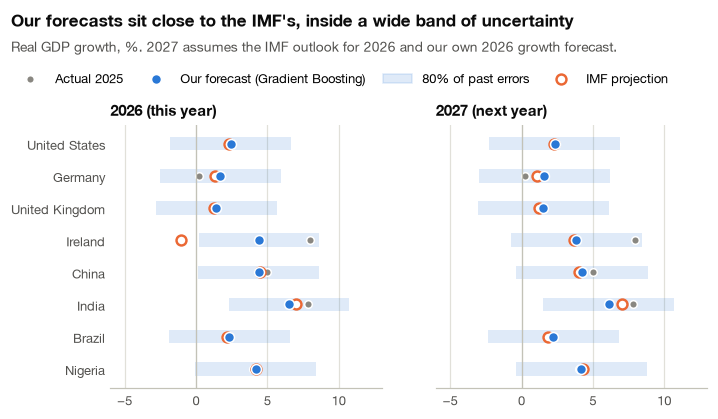

Saved outputs/forecasts_2026_2027.csv and outputs/scenarios_2027.csv


In [23]:
SHOW = ["USA", "DEU", "GBR", "IRL", "CHN", "IND", "BRA", "NGA"]
rows_ = fc.loc[[c for c in SHOW if c in fc.index]].iloc[::-1]
y = np.arange(len(rows_))
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), sharey=True, sharex=True)
for ax, yr, band in zip(axes, [2026, 2027], [band_1y, band_2y]):
    ours, theirs = rows_[f"Gradient Boosting {yr}"], rows_[f"IMF {yr}"]
    ax.barh(y, 2 * band, left=ours - band, height=0.42, color=BLUE, alpha=0.15, lw=0)
    ax.plot(rows_["growth 2025"], y, "o", color=MUTED, ms=5, mec="white", mew=1)
    ax.plot(theirs, y, "o", mfc="white", mec=ORANGE, mew=1.6, ms=6.5)
    ax.plot(ours, y, "o", color=BLUE, ms=6.5, mec="white", mew=1)
    ax.axvline(0, color=AXIS, lw=0.8); ax.xaxis.grid(True); ax.spines["left"].set_visible(False)
    ax.set_title(f"{yr} ({'this' if yr == 2026 else 'next'} year)", loc="left", fontsize=9.5, fontweight="bold", color=INK)
axes[0].set_yticks(y, rows_["Country Name"]); axes[0].set_xlim(-6, 13)
handles = [plt.Line2D([], [], ls="", marker="o", color=MUTED, ms=5, mec="white"),
           plt.Line2D([], [], ls="", marker="o", color=BLUE, ms=6.5, mec="white"),
           plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.15),
           plt.Line2D([], [], ls="", marker="o", mfc="white", mec=ORANGE, mew=1.6, ms=6.5)]
headline(fig, "Our forecasts sit close to the IMF's, inside a wide band of uncertainty",
         "Real GDP growth, %. 2027 assumes the IMF outlook for 2026 and our own 2026 growth forecast.",
         handles, ["Actual 2025", "Our forecast (Gradient Boosting)", "80% of past errors", "IMF projection"], ncol=4, pad=22)
fig.savefig(OUT / "figures/forecast_2026_2027.png"); plt.show()

fc.round(3).to_csv(OUT / "forecasts_2026_2027.csv")
sc.round(3).to_csv(OUT / "scenarios_2027.csv")
print("Saved outputs/forecasts_2026_2027.csv and outputs/scenarios_2027.csv")

<a id="s8"></a>
## 8. Conclusions and limitations

**Findings**
1. **Normal years:** the models are about 10% more accurate than the best simple benchmark, each country's own average (backtest MAE 2.80 vs 3.11). The country-level bootstrap interval excludes zero.
2. **Turning points:** 2009, 2020 and 2021 defeat every method. Forecasting from last year's indicators cannot anticipate shocks or rebounds.
3. **Test 2021-2024:** the models and the average benchmarks are statistically tied. Without 2021, the models win clearly.
4. **Which model:** Random Forest and Gradient Boosting are tied. Their gap is smaller than the variation between random seeds. Both beat the linear models slightly.
5. **Features:** current GDP growth dominates. Lasso removes unemployment, inflation, government debt and current account. The lags and clipping help the linear models and are neutral for the tree models.
6. **Forecasts for 2026-2027:**
   - Our 2026 forecasts track the IMF's: median gap +0.24 pp, correlation 0.56.
   - They differ most where one-off effects dominate. For Ireland the IMF says -1.0% and we say +4.4%.
   - For 2027, only the growth assumption moves the Gradient Boosting forecast. Ridge also reacts to inflation, investment and population growth.
   - So scenario results depend mainly on what is assumed for 2026 growth.

**Limitations**
- The data are today's revised figures, not the real-time numbers forecasters had at the time.
- Income groups are today's classification.
- The IMF comparison is pending, and it slightly favours our models (see Section 5).
- The 2026-2027 forecasts mix IMF inputs into a model trained on World Bank data. 2027 also depends on assumed 2026 values, so it is a scenario, not a prediction.
- Errors are dominated by a few volatile economies, and annual data gives only about 3,500 training rows.

**Future work:** real-time data vintages, prediction intervals (quantile models), SHAP explanations, and adding leading indicators such as commodity prices to catch turning points.